# Análisis exploratorio de denuncias en Guatemala (2022–2025)

Este notebook realiza una primera exploración del conjunto de datos de denuncias utilizado en el proyecto de agrupamiento de municipios de Guatemala.

## Objetivos

- Comprender la estructura y granularidad del conjunto de datos.
- Validar calidad, consistencia y cobertura.
- Explorar la distribución temporal, territorial y por tipo de delito.
- Detectar consideraciones importantes antes de construir los indicadores para clustering.
- Preparar una matriz preliminar de municipios por delito.

> **Unidad original de cada fila:** departamento, municipio, año, mes, grado del delito y delito.  
> **Variable numérica:** cantidad agregada de denuncias.


## Consideraciones metodológicas iniciales

1. El archivo contiene únicamente combinaciones con al menos una denuncia. Por ello, la ausencia de una fila no debe interpretarse automáticamente como dato faltante: puede representar **cero denuncias**.
2. Para análisis mensuales, promedios y construcción de indicadores es necesario completar explícitamente las combinaciones no observadas con cero.
3. El archivo contiene conteos absolutos. Antes de aplicar clustering será recomendable incorporar población municipal y calcular tasas comparables, por ejemplo, denuncias por cada 100,000 habitantes.
4. El conjunto contiene doce categorías en `Delito`. Si el proyecto trabajará finalmente con nueve delitos, deberá definirse de forma explícita cuáles se seleccionan o consolidan.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

MESES_ORDEN = ["ene", "feb", "mar", "abr", "may", "jun",
               "jul", "ago", "sep", "oct", "nov", "dic"]

NUMERO_MES = {mes: numero for numero, mes in enumerate(MESES_ORDEN, start=1)}


## 1. Carga del conjunto de datos

In [ ]:
# El notebook busca el archivo en ubicaciones comunes.
rutas_posibles = [
    Path("../../data/raw/denuncias_2022_2025.csv")
]

ruta_datos = next((ruta for ruta in rutas_posibles if ruta.exists()), None)

if ruta_datos is None:
    raise FileNotFoundError(
        "No se encontró denuncias_2022_2025.csv. "
        "Coloque el CSV junto al notebook o dentro de una carpeta llamada data."
    )

df_original = pd.read_csv(ruta_datos, encoding="utf-8")
df = df_original.copy()

print(f"Archivo utilizado: {ruta_datos.resolve()}")
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
display(df.head())


AttributeError: 'str' object has no attribute 'resolve'

### Diccionario inicial de variables

| Variable | Descripción esperada |
|---|---|
| `Departamento` | Departamento de Guatemala |
| `Municipio` | Municipio donde se registra la denuncia |
| `Anio` | Año del registro |
| `Mes` | Mes abreviado |
| `Grado_Delito` | Forma de realización registrada |
| `Delito` | Categoría delictiva |
| `Denuncias` | Cantidad agregada de denuncias |


In [ ]:
perfil_columnas = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "valores_no_nulos": df.notna().sum(),
    "valores_nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean().mul(100),
    "valores_unicos": df.nunique(dropna=False),
})

display(perfil_columnas)


,tipo_dato,valores_no_nulos,valores_nulos,porcentaje_nulos,valores_unicos
Departamento,object,75973,0,0.00,22
Municipio,object,75973,0,0.00,334
Anio,int64,75973,0,0.00,4
Mes,object,75973,0,0.00,12
Grado_Delito,object,75973,0,0.00,3
Delito,object,75973,0,0.00,12
Denuncias,float64,75973,0,0.00,369


## 2. Validación de calidad y consistencia

In [ ]:
columnas_esperadas = [
    "Departamento", "Municipio", "Anio", "Mes",
    "Grado_Delito", "Delito", "Denuncias"
]

faltantes_esquema = sorted(set(columnas_esperadas) - set(df.columns))
extras_esquema = sorted(set(df.columns) - set(columnas_esperadas))

print("Columnas esperadas ausentes:", faltantes_esquema)
print("Columnas adicionales:", extras_esquema)
print("Duplicados exactos:", df.duplicated().sum())
print("Valores nulos totales:", df.isna().sum().sum())


Columnas esperadas ausentes: []
Columnas adicionales: []
Duplicados exactos: 0
Valores nulos totales: 0


In [ ]:
llave_registro = [
    "Departamento", "Municipio", "Anio", "Mes",
    "Grado_Delito", "Delito"
]

duplicados_llave = df.duplicated(subset=llave_registro, keep=False)

print("Filas involucradas en llaves duplicadas:", duplicados_llave.sum())

if duplicados_llave.any():
    display(
        df.loc[duplicados_llave]
          .sort_values(llave_registro)
          .head(20)
    )


Filas involucradas en llaves duplicadas: 0


In [ ]:
columnas_texto = ["Departamento", "Municipio", "Mes", "Grado_Delito", "Delito"]

revision_texto = []
for columna in columnas_texto:
    serie = df[columna].astype("string")
    revision_texto.append({
        "columna": columna,
        "espacios_extremos": (serie != serie.str.strip()).sum(),
        "cadenas_vacias": serie.str.strip().eq("").sum(),
    })

display(pd.DataFrame(revision_texto))


,columna,espacios_extremos,cadenas_vacias
0,Departamento,0,0
1,Municipio,0,0
2,Mes,0,0
3,Grado_Delito,0,0
4,Delito,0,0


In [ ]:
revision_denuncias = pd.Series({
    "mínimo": df["Denuncias"].min(),
    "máximo": df["Denuncias"].max(),
    "valores_negativos": (df["Denuncias"] < 0).sum(),
    "valores_cero": (df["Denuncias"] == 0).sum(),
    "valores_no_enteros": ((df["Denuncias"] % 1) != 0).sum(),
}, name="resultado")

display(revision_denuncias.to_frame())


,resultado
mínimo,1.00
máximo,"1,372.00"
valores_negativos,0.00
valores_cero,0.00
valores_no_enteros,0.00


### Cobertura de categorías

In [ ]:
print("Años:", sorted(df["Anio"].unique().tolist()))
print("Meses:", df["Mes"].value_counts().reindex(MESES_ORDEN).index.tolist())
print("Departamentos:", df["Departamento"].nunique())
print("Nombres únicos de municipio:", df["Municipio"].nunique())
print(
    "Pares departamento–municipio:",
    df[["Departamento", "Municipio"]].drop_duplicates().shape[0]
)
print("Grados del delito:", df["Grado_Delito"].nunique())
print("Categorías de delito:", df["Delito"].nunique())

display(
    df["Delito"]
      .value_counts()
      .rename_axis("Delito")
      .reset_index(name="filas_observadas")
)


Años: [2022, 2023, 2024, 2025]
Meses: ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']
Departamentos: 22
Nombres únicos de municipio: 334
Pares departamento–municipio: 340
Grados del delito: 3
Categorías de delito: 12


,Delito,filas_observadas
0,Extorsión,14285
1,Hurto,12293
2,Hurto agravado,9468
3,Robo agravado,8242
4,Violación,8083
5,Robo,7728
6,Homicidio,5897
7,Agresión sexual,4898
8,Asesinato,1846
9,Violación agravada,1778


### Municipios con nombres repetidos

El nombre del municipio no es una llave suficiente porque existen municipios homónimos en diferentes departamentos. Para evitar mezclas durante el análisis se crea un identificador compuesto `Departamento | Municipio`.


In [ ]:
municipio_departamento = (
    df[["Departamento", "Municipio"]]
    .drop_duplicates()
    .groupby("Municipio")["Departamento"]
    .agg(list)
)

municipios_homonimos = municipio_departamento[
    municipio_departamento.map(len) > 1
]

display(municipios_homonimos.to_frame("departamentos"))


,departamentos
Municipio,
La Democracia,"[Escuintla, Huehuetenango]"
La Libertad,"[Huehuetenango, Petén]"
San José,"[Escuintla, Petén]"
San Lorenzo,"[San Marcos, Suchitepéquez]"
San Pedro Sacatepéquez,"[Guatemala, San Marcos]"
Santa Bárbara,"[Huehuetenango, Suchitepéquez]"


## 3. Preparación básica para el análisis

In [ ]:
# Limpieza defensiva.
for columna in columnas_texto:
    df[columna] = df[columna].astype("string").str.strip()

df["Anio"] = pd.to_numeric(df["Anio"], errors="raise").astype("int64")
df["Denuncias"] = pd.to_numeric(df["Denuncias"], errors="raise").astype("int64")

# Orden cronológico y fecha mensual.
df["Mes"] = pd.Categorical(df["Mes"], categories=MESES_ORDEN, ordered=True)
df["Numero_Mes"] = df["Mes"].astype("string").map(NUMERO_MES).astype("int64")
df["Fecha"] = pd.to_datetime(
    dict(year=df["Anio"], month=df["Numero_Mes"], day=1)
)

# Identificador territorial no ambiguo.
df["Municipio_ID"] = (
    df["Departamento"].astype("string")
    + " | "
    + df["Municipio"].astype("string")
)

df = df.sort_values(
    ["Fecha", "Departamento", "Municipio", "Delito", "Grado_Delito"]
).reset_index(drop=True)

display(df.head())


,Departamento,Municipio,Anio,Mes,Grado_Delito,Delito,Denuncias,Numero_Mes,Fecha,Municipio_ID
0,Alta Verapaz,Chahal,2022,ene,Consumado,Hurto agravado,3,1,2022-01-01,Alta Verapaz | Chahal
1,Alta Verapaz,Chahal,2022,ene,Consumado,Violación,1,1,2022-01-01,Alta Verapaz | Chahal
2,Alta Verapaz,Chisec,2022,ene,Consumado,Asesinato,1,1,2022-01-01,Alta Verapaz | Chisec
3,Alta Verapaz,Chisec,2022,ene,Consumado,Hurto,2,1,2022-01-01,Alta Verapaz | Chisec
4,Alta Verapaz,Chisec,2022,ene,Tentativa,Hurto,1,1,2022-01-01,Alta Verapaz | Chisec


## 4. Resumen general

In [ ]:
resumen_general = pd.Series({
    "filas": len(df),
    "denuncias_totales": df["Denuncias"].sum(),
    "años": df["Anio"].nunique(),
    "departamentos": df["Departamento"].nunique(),
    "municipios_departamento": df["Municipio_ID"].nunique(),
    "delitos": df["Delito"].nunique(),
    "grados_delito": df["Grado_Delito"].nunique(),
}, name="valor")

display(resumen_general.to_frame())
display(df["Denuncias"].describe().to_frame())


,valor
filas,75973
denuncias_totales,435043
años,4
departamentos,22
municipios_departamento,340
delitos,12
grados_delito,3


,Denuncias
count,"75,973.00"
mean,5.73
std,33.06
min,1.00
25%,1.00
50%,2.00
75%,3.00
max,"1,372.00"


La distribución de `Denuncias` por fila debe interpretarse con cuidado: una fila representa una combinación agregada y el archivo no incluye filas con cero. Por ello, los estadísticos anteriores describen solamente combinaciones observadas.


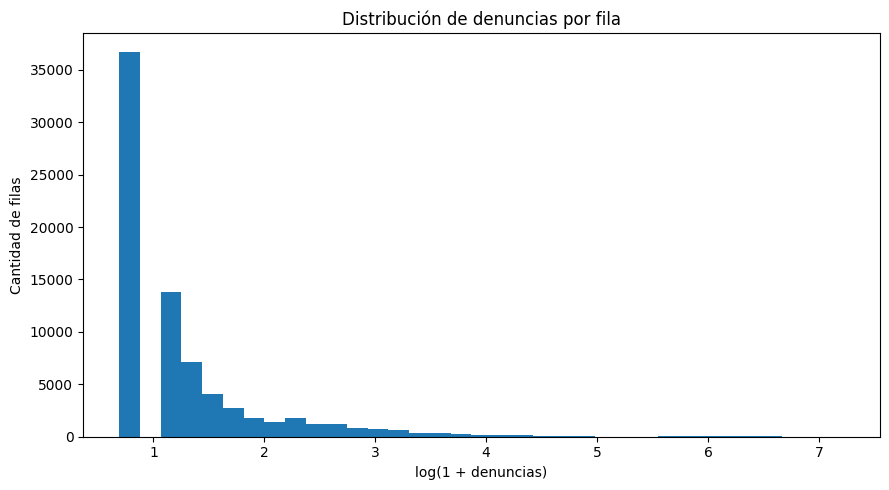

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(np.log1p(df["Denuncias"]), bins=35)
ax.set_title("Distribución de denuncias por fila")
ax.set_xlabel("log(1 + denuncias)")
ax.set_ylabel("Cantidad de filas")
plt.tight_layout()
plt.show()


## 5. Exploración temporal

,Denuncias
Anio,
2022,105138
2023,111637
2024,115576
2025,102692


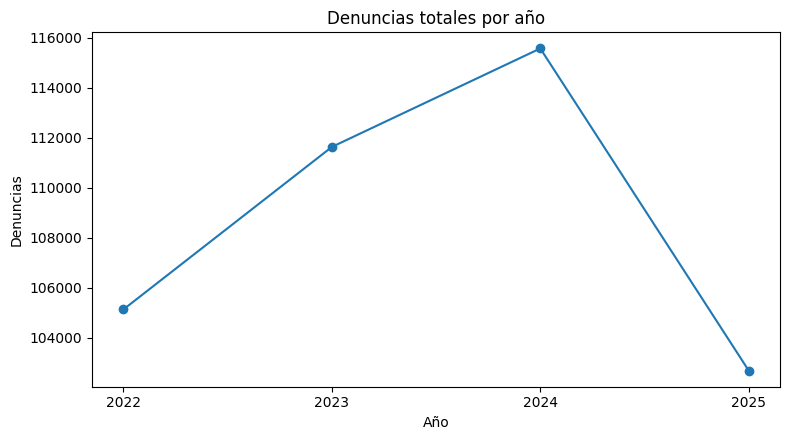

In [ ]:
denuncias_anuales = (
    df.groupby("Anio", observed=True)["Denuncias"]
      .sum()
      .sort_index()
)

display(denuncias_anuales.to_frame("Denuncias"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(denuncias_anuales.index, denuncias_anuales.values, marker="o")
ax.set_title("Denuncias totales por año")
ax.set_xlabel("Año")
ax.set_ylabel("Denuncias")
ax.set_xticks(denuncias_anuales.index)
plt.tight_layout()
plt.show()


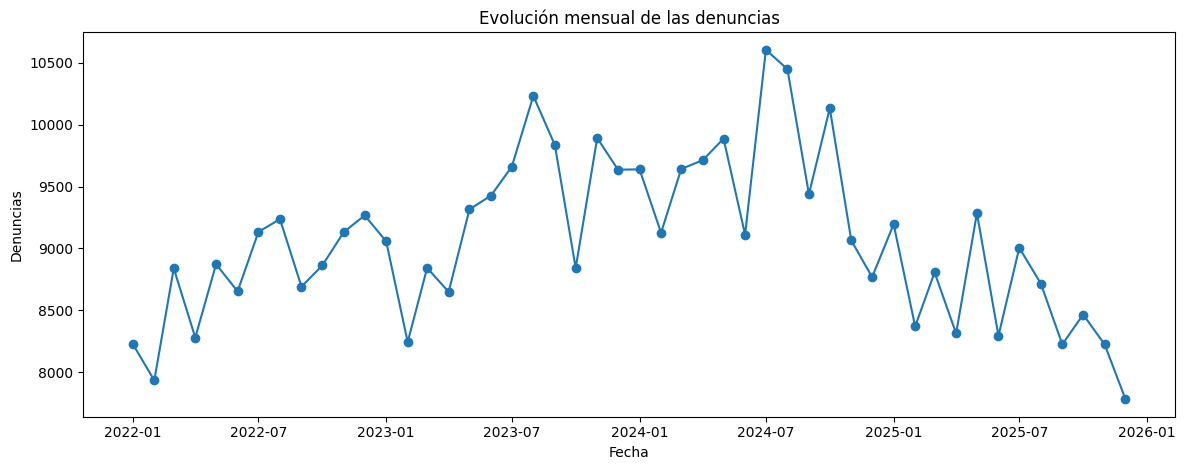

,Denuncias
Fecha,
2025-01-01,9196
2025-02-01,8371
2025-03-01,8807
2025-04-01,8314
2025-05-01,9285
2025-06-01,8295
2025-07-01,9006
2025-08-01,8717
2025-09-01,8226


In [ ]:
denuncias_mensuales = (
    df.groupby("Fecha", observed=True)["Denuncias"]
      .sum()
      .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(denuncias_mensuales.index, denuncias_mensuales.values, marker="o")
ax.set_title("Evolución mensual de las denuncias")
ax.set_xlabel("Fecha")
ax.set_ylabel("Denuncias")
plt.tight_layout()
plt.show()

display(denuncias_mensuales.to_frame().tail(12))


In [ ]:
tabla_anio_mes = (
    df.pivot_table(
        index="Anio",
        columns="Mes",
        values="Denuncias",
        aggfunc="sum",
        fill_value=0,
        observed=True,
    )
    .reindex(columns=MESES_ORDEN)
)

display(tabla_anio_mes)


Mes,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
Anio,,,,,,,,,,,,
2022,8229,7935,8840,8281,8873,8654,9134,9237,8692,8863,9133,9267
2023,9058,8245,8843,8650,9316,9427,9661,10232,9835,8842,9892,9636
2024,9639,9127,9642,9713,9887,9112,10604,10448,9438,10132,9065,8769
2025,9196,8371,8807,8314,9285,8295,9006,8717,8226,8467,8225,7783


## 6. Exploración por delito

,Denuncias
Delito,
Hurto,113190
Extorsión,84597
Robo agravado,65500
Hurto agravado,61839
Robo,61676
Violación,17930
Homicidio,13812
Agresión sexual,8994
Asesinato,3432


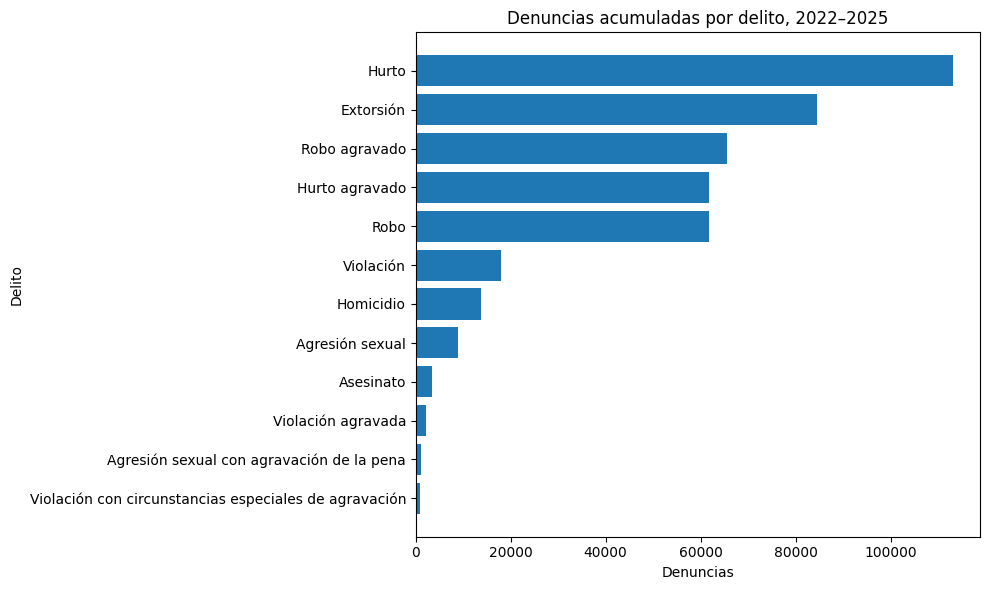

In [ ]:
denuncias_delito = (
    df.groupby("Delito", observed=True)["Denuncias"]
      .sum()
      .sort_values()
)

display(denuncias_delito.sort_values(ascending=False).to_frame())

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(denuncias_delito.index, denuncias_delito.values)
ax.set_title("Denuncias acumuladas por delito, 2022–2025")
ax.set_xlabel("Denuncias")
ax.set_ylabel("Delito")
plt.tight_layout()
plt.show()


In [ ]:
delito_anio = df.pivot_table(
    index="Delito",
    columns="Anio",
    values="Denuncias",
    aggfunc="sum",
    fill_value=0,
    observed=True,
)

delito_anio["Total_2022_2025"] = delito_anio.sum(axis=1)
delito_anio["Variacion_2022_2025_pct"] = np.where(
    delito_anio[2022] == 0,
    np.nan,
    (delito_anio[2025] - delito_anio[2022]) / delito_anio[2022] * 100,
)

display(delito_anio.sort_values("Total_2022_2025", ascending=False))


Anio,2022,2023,2024,2025,Total_2022_2025,Variacion_2022_2025_pct
Delito,,,,,,
Hurto,24659,30925,32593,25013,113190,1.44
Extorsión,14928,18416,24714,26539,84597,77.78
Robo agravado,18197,17630,15317,14356,65500,-21.11
Hurto agravado,15841,16779,15443,13776,61839,-13.04
Robo,18066,15570,16103,11937,61676,-33.93
Violación,5500,4668,4039,3723,17930,-32.31
Homicidio,3470,3467,3350,3525,13812,1.59
Agresión sexual,2571,2282,2180,1961,8994,-23.73
Asesinato,814,827,821,970,3432,19.16


## 7. Exploración territorial

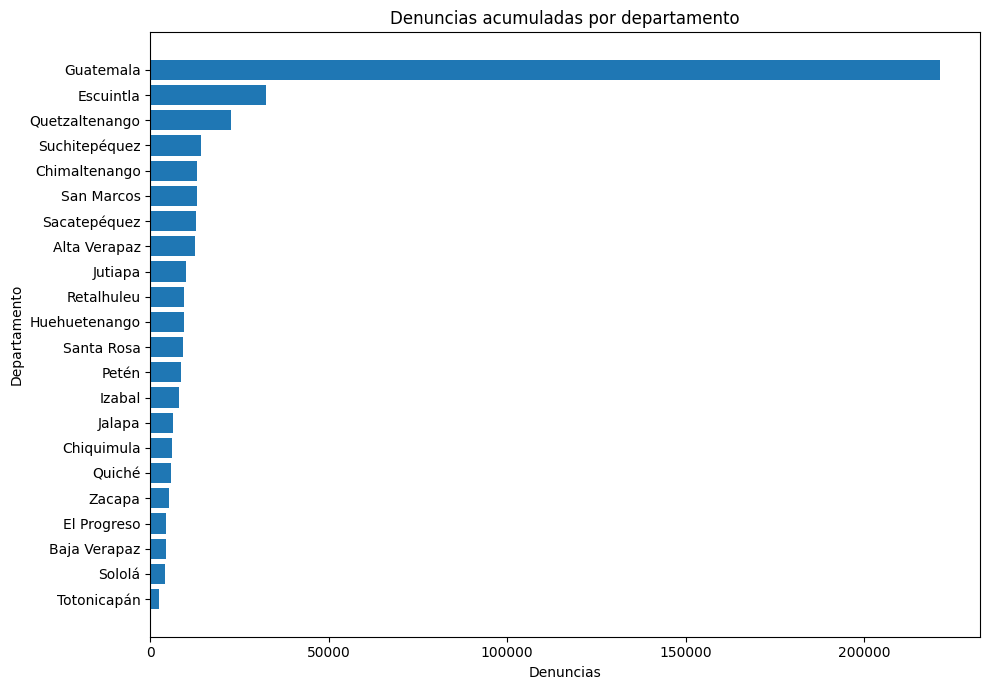

,Denuncias
Departamento,
Guatemala,221425
Escuintla,32366
Quetzaltenango,22580
Suchitepéquez,14049
Chimaltenango,13094
San Marcos,13004
Sacatepéquez,12702
Alta Verapaz,12417
Jutiapa,10078


In [ ]:
denuncias_departamento = (
    df.groupby("Departamento", observed=True)["Denuncias"]
      .sum()
      .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(denuncias_departamento.index, denuncias_departamento.values)
ax.set_title("Denuncias acumuladas por departamento")
ax.set_xlabel("Denuncias")
ax.set_ylabel("Departamento")
plt.tight_layout()
plt.show()

display(
    denuncias_departamento.sort_values(ascending=False)
    .to_frame()
)


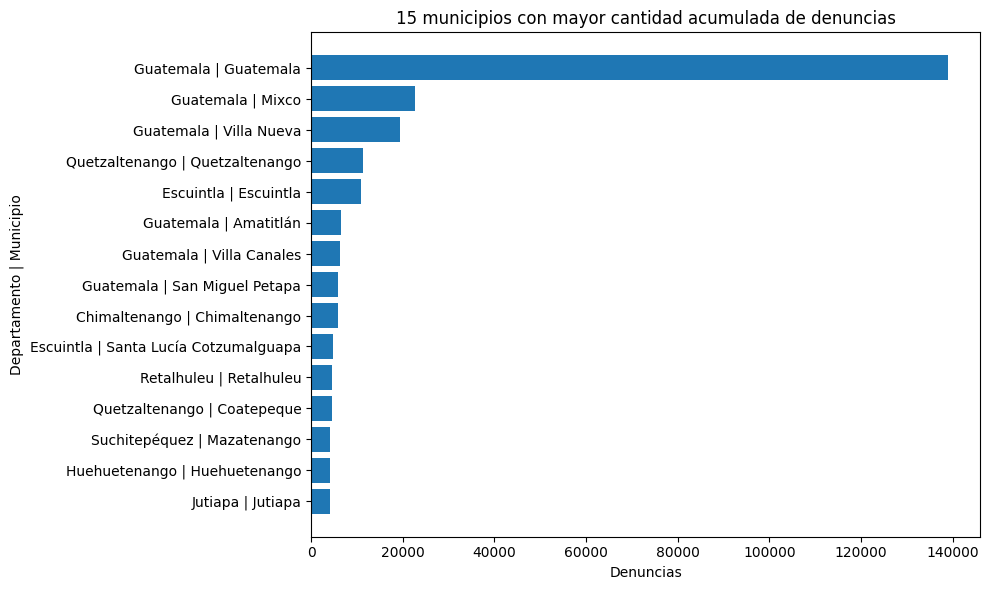

Denuncias
Departamento   Municipio                 Municipio_ID                                    
Guatemala      Guatemala                 Guatemala | Guatemala                     139031
               Mixco                     Guatemala | Mixco                          22587
               Villa Nueva               Guatemala | Villa Nueva                    19514
Quetzaltenango Quetzaltenango            Quetzaltenango | Quetzaltenango            11238
Escuintla      Escuintla                 Escuintla | Escuintla                      10801
Guatemala      Amatitlán                 Guatemala | Amatitlán                       6445
               Villa Canales             Guatemala | Villa Canales                   6237
               San Miguel Petapa         Guatemala | San Miguel Petapa               5930
Chimaltenango  Chimaltenango             Chimaltenango | Chimaltenango               5820
Escuintla      Santa Lucía Cotzumalguapa Escuintla | Santa Lucía Cotzumalguapa       4700
Retalhuleu     Retalhuleu                Retalhuleu | Retalhuleu                     4522
Quetzaltenango Coatepeque                Quetzaltenango | Coatepeque                 4500
Suchitepéquez  Mazatenango               Suchitepéquez | Mazatenango                 4241
Huehuetenango  Huehuetenango             Huehuetenango | Huehuetenango               4222
Jutiapa        Jutiapa                   Jutiapa | Jutiapa                           4052
Izabal         Puerto Barrios            Izabal | Puerto Barrios                     4037
Alta Verapaz   Cobán                     Alta Verapaz | Cobán                        4014
Jalapa         Jalapa                    Jalapa | Jalapa                             4009
Guatemala      Chinautla                 Guatemala | Chinautla                       3858
               San José Pinula           Guatemala | San José Pinula                 3769

In [ ]:
denuncias_municipio = (
    df.groupby(["Departamento", "Municipio", "Municipio_ID"], observed=True)["Denuncias"]
      .sum()
      .sort_values(ascending=False)
)

top_municipios = denuncias_municipio.head(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    [indice[2] for indice in top_municipios.index],
    top_municipios.values,
)
ax.set_title("15 municipios con mayor cantidad acumulada de denuncias")
ax.set_xlabel("Denuncias")
ax.set_ylabel("Departamento | Municipio")
plt.tight_layout()
plt.show()

display(denuncias_municipio.head(20).to_frame())


Los conteos territoriales anteriores todavía no controlan por población. Es esperable que municipios con mayor población o actividad urbana acumulen más denuncias. Para comparar niveles relativos de incidencia se necesitará construir tasas.


## 8. Exploración por grado del delito

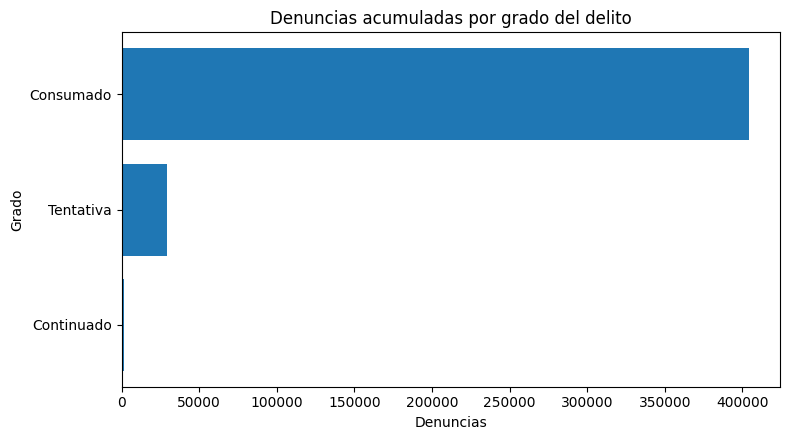

,Denuncias
Grado_Delito,
Consumado,404106
Tentativa,29378
Continuado,1559


In [ ]:
denuncias_grado = (
    df.groupby("Grado_Delito", observed=True)["Denuncias"]
      .sum()
      .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(denuncias_grado.index, denuncias_grado.values)
ax.set_title("Denuncias acumuladas por grado del delito")
ax.set_xlabel("Denuncias")
ax.set_ylabel("Grado")
plt.tight_layout()
plt.show()

display(denuncias_grado.sort_values(ascending=False).to_frame())


## 9. Reconstrucción de combinaciones con cero denuncias

Para evitar promedios sesgados, primero se agregan los grados del delito y luego se construye una cuadrícula completa:

**municipio × año × mes × delito**

Las combinaciones que no aparecen en el CSV se rellenan con cero. No se completa una cuadrícula por `Grado_Delito`, porque algunas categorías podrían no aplicar estructuralmente a todos los delitos.


In [ ]:
# Agregación mensual por delito, sumando los grados registrados.
mensual_observado = (
    df.groupby(
        ["Departamento", "Municipio", "Municipio_ID", "Anio", "Mes", "Delito"],
        observed=True,
        as_index=False,
    )["Denuncias"]
    .sum()
)

territorios = df[
    ["Departamento", "Municipio", "Municipio_ID"]
].drop_duplicates()

anios = pd.DataFrame({"Anio": sorted(df["Anio"].unique())})
meses = pd.DataFrame({"Mes": MESES_ORDEN})
delitos = pd.DataFrame({"Delito": sorted(df["Delito"].unique())})

cuadricula = (
    territorios
    .merge(anios, how="cross")
    .merge(meses, how="cross")
    .merge(delitos, how="cross")
)

mensual_completo = cuadricula.merge(
    mensual_observado,
    on=["Departamento", "Municipio", "Municipio_ID", "Anio", "Mes", "Delito"],
    how="left",
)

mensual_completo["Denuncias"] = (
    mensual_completo["Denuncias"]
    .fillna(0)
    .astype("int64")
)

mensual_completo["Mes"] = pd.Categorical(
    mensual_completo["Mes"],
    categories=MESES_ORDEN,
    ordered=True,
)

mensual_completo["Numero_Mes"] = (
    mensual_completo["Mes"]
    .astype("string")
    .map(NUMERO_MES)
    .astype("int64")
)

mensual_completo["Fecha"] = pd.to_datetime(
    dict(
        year=mensual_completo["Anio"],
        month=mensual_completo["Numero_Mes"],
        day=1,
    )
)

print(f"Filas observadas después de agregar grados: {len(mensual_observado):,}")
print(f"Filas esperadas en la cuadrícula completa: {len(cuadricula):,}")
print(f"Filas con cero después de completar: {(mensual_completo['Denuncias'] == 0).sum():,}")
print(
    "¿Se conserva el total de denuncias?",
    mensual_completo["Denuncias"].sum() == df["Denuncias"].sum(),
)

display(mensual_completo.head())


Filas observadas después de agregar grados: 67,797
Filas esperadas en la cuadrícula completa: 195,840
Filas con cero después de completar: 128,043
¿Se conserva el total de denuncias? True


,Departamento,Municipio,Municipio_ID,Anio,Mes,Delito,Denuncias,Numero_Mes,Fecha
0,Alta Verapaz,Chahal,Alta Verapaz | Chahal,2022,ene,Agresión sexual,0,1,2022-01-01
1,Alta Verapaz,Chahal,Alta Verapaz | Chahal,2022,ene,Agresión sexual con agravación de la pena,0,1,2022-01-01
2,Alta Verapaz,Chahal,Alta Verapaz | Chahal,2022,ene,Asesinato,0,1,2022-01-01
3,Alta Verapaz,Chahal,Alta Verapaz | Chahal,2022,ene,Extorsión,0,1,2022-01-01
4,Alta Verapaz,Chahal,Alta Verapaz | Chahal,2022,ene,Homicidio,0,1,2022-01-01


In [ ]:
# Revisión de cobertura municipio-año.
cobertura_municipio_anio = (
    df[["Departamento", "Municipio", "Municipio_ID", "Anio"]]
    .drop_duplicates()
)

cuadricula_municipio_anio = territorios.merge(anios, how="cross")

municipio_anio_sin_filas = (
    cuadricula_municipio_anio
    .merge(
        cobertura_municipio_anio,
        on=["Departamento", "Municipio", "Municipio_ID", "Anio"],
        how="left",
        indicator=True,
    )
    .query("_merge == 'left_only'")
    .drop(columns="_merge")
)

display(municipio_anio_sin_filas)


,Departamento,Municipio,Municipio_ID,Anio
1356,Sololá,Concepción,Sololá | Concepción,2022


## 10. Matriz preliminar para el análisis municipal

La siguiente matriz resume el total acumulado de cada delito por municipio durante 2022–2025. Esta matriz es útil para explorar la forma de los datos, pero **todavía no debe utilizarse como entrada definitiva del clustering** hasta incorporar tasas poblacionales, revisar transformaciones y seleccionar los delitos finales.


In [ ]:
matriz_municipio_delito = (
    mensual_completo
    .pivot_table(
        index=["Departamento", "Municipio", "Municipio_ID"],
        columns="Delito",
        values="Denuncias",
        aggfunc="sum",
        fill_value=0,
        observed=True,
    )
    .sort_index()
)

matriz_municipio_delito["Total_Denuncias"] = matriz_municipio_delito.sum(axis=1)

print("Dimensiones de la matriz:", matriz_municipio_delito.shape)
display(matriz_municipio_delito.head())


Dimensiones de la matriz: (340, 13)


Delito                                                                               Agresión sexual  \
Departamento Municipio                   Municipio_ID                                                  
Alta Verapaz Chahal                      Alta Verapaz | Chahal                                    10   
             Chisec                      Alta Verapaz | Chisec                                    28   
             Cobán                       Alta Verapaz | Cobán                                    201   
             Fray Bartolomé de las Casas Alta Verapaz | Fray Bartolomé de las Casas               32   
             La Tinta                    Alta Verapaz | La Tinta                                  23   

Delito                                                                               Agresión sexual con agravación de la pena  \
Departamento Municipio                   Municipio_ID                                                                            
Alta Verapaz Chahal                      Alta Verapaz | Chahal                                                               1   
             Chisec                      Alta Verapaz | Chisec                                                               1   
             Cobán                       Alta Verapaz | Cobán                                                                7   
             Fray Bartolomé de las Casas Alta Verapaz | Fray Bartolomé de las Casas                                          0   
             La Tinta                    Alta Verapaz | La Tinta                                                             0   

Delito                                                                               Asesinato  \
Departamento Municipio                   Municipio_ID                                            
Alta Verapaz Chahal                      Alta Verapaz | Chahal                               5   
             Chisec                      Alta Verapaz | Chisec                               8   
             Cobán                       Alta Verapaz | Cobán                               26   
             Fray Bartolomé de las Casas Alta Verapaz | Fray Bartolomé de las Casas          2   
             La Tinta                    Alta Verapaz | La Tinta                             2   

Delito                                                                               Extorsión  \
Departamento Municipio                   Municipio_ID                                            
Alta Verapaz Chahal                      Alta Verapaz | Chahal                              67   
             Chisec                      Alta Verapaz | Chisec                             119   
             Cobán                       Alta Verapaz | Cobán                              983   
             Fray Bartolomé de las Casas Alta Verapaz | Fray Bartolomé de las Casas        102   
             La Tinta                    Alta Verapaz | La Tinta                            79   

Delito                                                                               Homicidio  \
Departamento Municipio                   Municipio_ID                                            
Alta Verapaz Chahal                      Alta Verapaz | Chahal                              13   
             Chisec                      Alta Verapaz | Chisec                              22   
             Cobán                       Alta Verapaz | Cobán                              101   
             Fray Bartolomé de las Casas Alta Verapaz | Fray Bartolomé de las Casas         21   
             La Tinta                    Alta Verapaz | La Tinta                            14   

Delito                                                                               Hurto  \
Departamento Municipio                   Municipio_ID                                        
Alta Verapaz Chahal                      Alta Verapaz | Chahal                          29   
             Chis

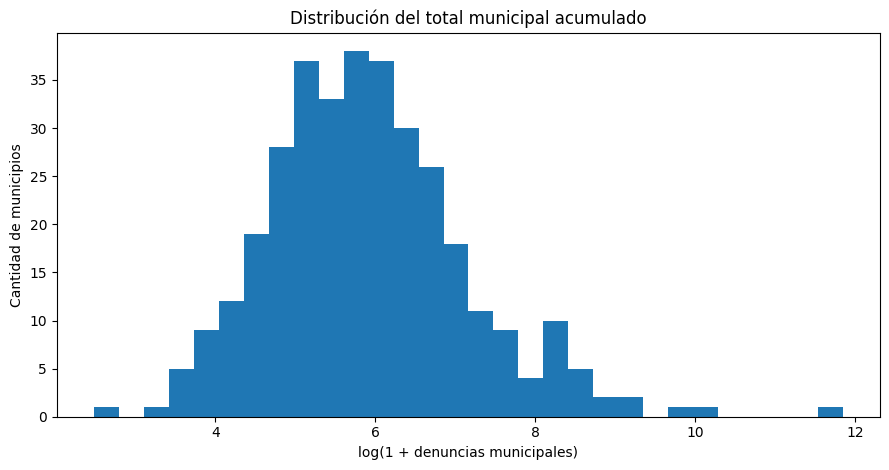

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(np.log1p(matriz_municipio_delito["Total_Denuncias"]), bins=30)
ax.set_title("Distribución del total municipal acumulado")
ax.set_xlabel("log(1 + denuncias municipales)")
ax.set_ylabel("Cantidad de municipios")
plt.tight_layout()
plt.show()


## 11. Selección de delitos del proyecto

In [ ]:
# El archivo contiene doce categorías.
delitos_disponibles = sorted(df["Delito"].unique())

print(f"Categorías disponibles: {len(delitos_disponibles)}")
for delito in delitos_disponibles:
    print("-", delito)

# Sustituir esta lista por los nueve delitos definitivos del proyecto.
DELITOS_SELECCIONADOS = delitos_disponibles.copy()

df_seleccion = df[df["Delito"].isin(DELITOS_SELECCIONADOS)].copy()

print(
    f"Se conservaron {df_seleccion['Delito'].nunique()} delitos "
    f"y {len(df_seleccion):,} filas."
)


Categorías disponibles: 12
- Agresión sexual
- Agresión sexual con agravación de la pena
- Asesinato
- Extorsión
- Homicidio
- Hurto
- Hurto agravado
- Robo
- Robo agravado
- Violación
- Violación agravada
- Violación con circunstancias especiales de agravación


Se conservaron 12 delitos y 75,973 filas.


## 12. Próximos pasos recomendados

1. Confirmar los nueve delitos definitivos y documentar cualquier consolidación.
2. Incorporar población por municipio y año.
3. Calcular tasas por cada 100,000 habitantes.
4. Decidir la unidad para clustering:
   - una observación por municipio usando todo el período; o
   - una observación por municipio-año.
5. Crear indicadores por delito, por ejemplo:
   - tasa promedio;
   - variabilidad temporal;
   - tendencia;
   - proporción respecto del total municipal.
6. Evaluar asimetría y valores extremos.
7. Comparar escalamiento estándar, robusto y transformaciones logarítmicas.
8. Analizar correlaciones y redundancia entre variables.
9. Preparar las matrices para K-means, clustering jerárquico y modelos de mezcla gaussiana.
10. Evaluar los resultados mediante Silhouette, Davies–Bouldin y Calinski–Harabasz.

### Advertencia central

Aplicar clustering directamente sobre conteos absolutos probablemente separará municipios principalmente por tamaño poblacional y concentración urbana. La normalización territorial es una etapa fundamental para que los conglomerados representen patrones delictivos comparables.
